# Remake -- training data preparation

Input: `cache/remake_dataset.parquet`, built by `remake_dataset.ipynb`.

Processing follows `final.ipynb` section 14. Steps that were already done
when the dataset was built are **not** repeated:

- Row filters (zoning, units of use, freehold, single-property, arm's-length,
  LINZ-matched) and removal of exact duplicate sales.
- Leakage columns removed (`capital_value`, `land_value`, net/chattels/other price).
- Categorical columns cast to string, missing filled with `"Unknown"`.
- `log1p` already applied to `land_area`, `building_total_floor_area`,
  `mass_total_floor_area`, `walk_supermarket_network_m`, `walk_bus_stop_network_m`
  -- applying it again here would double-log them.

What remains is done **inside each time-based fold, fitted on the training
rows only**, exactly as in `final.ipynb`: category encoding, bool to int,
median fill for missing numbers, and the 1st/99th-percentile price trim.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,711 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [2]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month", "sale_quarter",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET}
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

29 features: 5 categorical, 1 boolean, 23 numeric


## 2. Missing values before processing

In [3]:
na = df[FEATURE_COLS + [TARGET]].isna().sum()
na[na > 0].to_frame("missing rows")

,missing rows
walk_supermarket_network_m,1596
walk_bus_stop_network_m,852


## 3. Per-fold processing (same steps as `final.ipynb` section 14.3)

Everything is learned from the training rows of a fold and then applied to
that fold's test rows, so no information from the test period leaks in.

In [4]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 4. Build the 5 folds and check them

In [5]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,780


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9764,9777,450000.0,4511250.0
2,2024-11-07,2024-11-07 to 2025-04-01,19508,9683,450000.0,4248800.0
3,2025-04-01,2025-04-01 to 2025-08-22,29266,9785,430000.0,4285750.0
4,2025-08-22,2025-08-22 to 2026-01-25,39013,9761,433000.0,4218800.0
5,2026-01-25,2026-01-25 to 2026-08-18,48799,9774,430000.0,4200000.0


## 5. Train Random Forest, XGBoost and CatBoost

All three are trained on the same 5 folds and the same processed inputs, so
differences come from the model, not the data. Settings are fixed (not
tuned per model): Random Forest and XGBoost use the same settings as the
rest of this project (`loc_exp.ipynb`, `final.ipynb`); CatBoost is set to
match XGBoost (500 trees, depth 6, learning rate 0.05).

CatBoost could encode categories itself, but here it gets the same
integer-coded inputs as the other two to keep the comparison fair.

In [6]:
import time
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


MODELS = {
    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=150, max_depth=18, min_samples_leaf=2, n_jobs=-1, random_state=42,
    ),
    "XGBoost": lambda: XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
    ),
    "CatBoost": lambda: CatBoostRegressor(
        iterations=500, depth=6, learning_rate=0.05, random_seed=42, thread_count=-1, verbose=0,
    ),
}

oof = pd.DataFrame(
    {
        "actual": np.concatenate([f["y_test"] for f in folds]),
        "fold": np.concatenate([np.full(len(f["y_test"]), i) for i, f in enumerate(folds, start=1)]),
    },
    index=np.concatenate([f["test_idx"] for f in folds]),
)
fold_rows = []
train_seconds = {}

for name, make_model in MODELS.items():
    start = time.time()
    preds = []
    for fold_i, f in enumerate(folds, start=1):
        model = make_model()
        model.fit(f["X_train"], f["y_train"])
        pred = model.predict(f["X_test"])
        preds.append(pred)
        fold_rows.append({
            "model": name, "fold": fold_i,
            "RMSE": rmse(f["y_test"], pred), "MAE": mae(f["y_test"], pred), "MAPE": mape(f["y_test"], pred),
        })
    oof[name] = np.concatenate(preds)
    train_seconds[name] = time.time() - start
    print(f"{name}: 5 folds done in {train_seconds[name]:.0f}s")

RandomForest: 5 folds done in 16s


XGBoost: 5 folds done in 4s


CatBoost: 5 folds done in 10s


### 5.1 Pooled results (all 5 folds' test predictions combined)

In [7]:
results = pd.DataFrame([
    {
        "model": name,
        "RMSE": rmse(oof["actual"], oof[name]),
        "MAE": mae(oof["actual"], oof[name]),
        "MAPE": mape(oof["actual"], oof[name]),
        "train_time_s": train_seconds[name],
    }
    for name in MODELS
]).set_index("model").sort_values("RMSE")
print(f"Pooled over {len(oof):,} test predictions")
results.round(2)

Pooled over 48,780 test predictions


,RMSE,MAE,MAPE,train_time_s
model,,,,
XGBoost,212887.20,127633.58,10.93,4.27
CatBoost,219741.04,134815.39,11.60,9.83
RandomForest,227769.99,134821.63,11.56,15.78


In [8]:
fold_results = pd.DataFrame(fold_rows)
print("RMSE by fold:")
fold_results.pivot(index="fold", columns="model", values="RMSE").round(0)

RMSE by fold:


model,CatBoost,RandomForest,XGBoost
fold,,,
1,243096.0,258629.0,240994.0
2,223140.0,234793.0,218450.0
3,217547.0,221957.0,207122.0
4,211276.0,215640.0,203051.0
5,201460.0,204046.0,191554.0


## 6. SHAP per model

Each model is refit on **fold 5** (the latest fold: trained on everything up
to January 2026, tested on January -- August 2026), then explained with
`shap.TreeExplainer` on the **same 500 test sales** for all three models, so
the rankings are directly comparable. Same sample size and seed as
`final.ipynb` section 17.3.

In [9]:
import shap
import matplotlib.pyplot as plt

shap_fold = folds[-1]
shap_sample = shap_fold["X_test"].sample(n=500, random_state=42)

shap_values = {}
for name, make_model in MODELS.items():
    start = time.time()
    model = make_model()
    model.fit(shap_fold["X_train"], shap_fold["y_train"])
    shap_values[name] = shap.TreeExplainer(model).shap_values(shap_sample)
    print(f"{name}: SHAP done in {time.time() - start:.0f}s")

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RandomForest: SHAP done in 270s


XGBoost: SHAP done in 1s


CatBoost: SHAP done in 2s


### 6.1 Summary plot per model

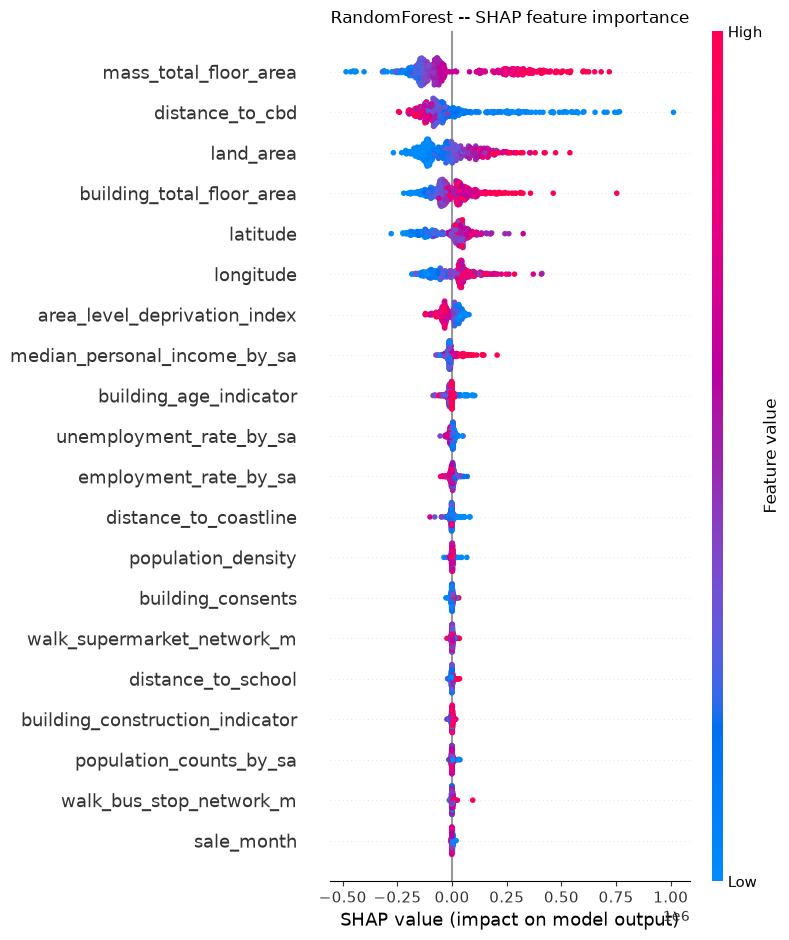

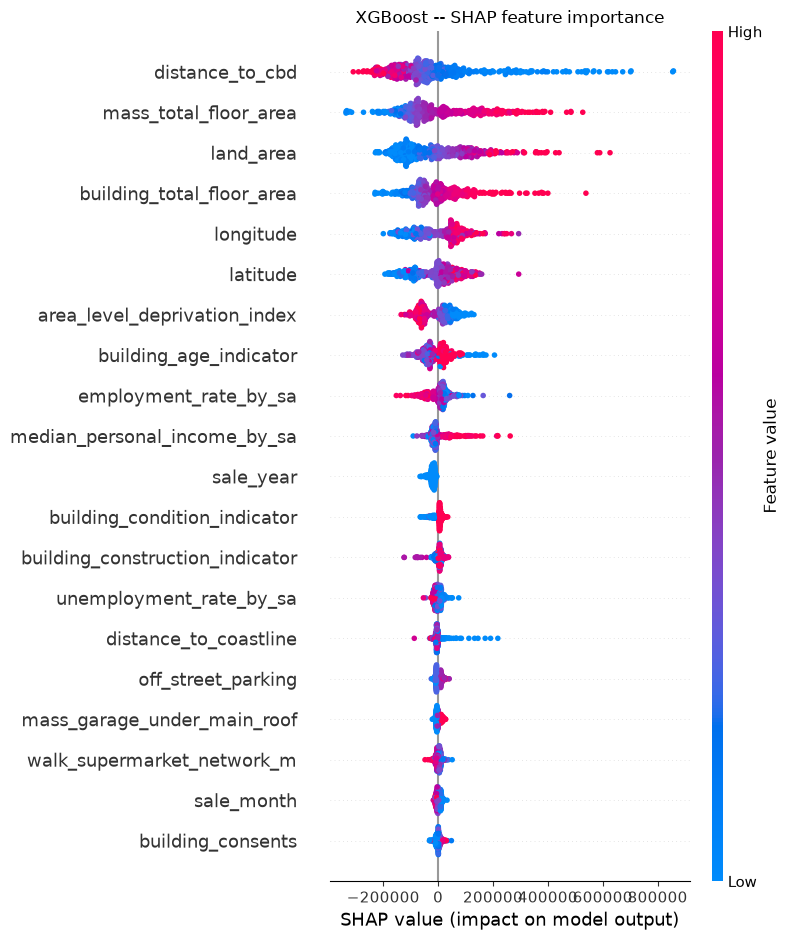

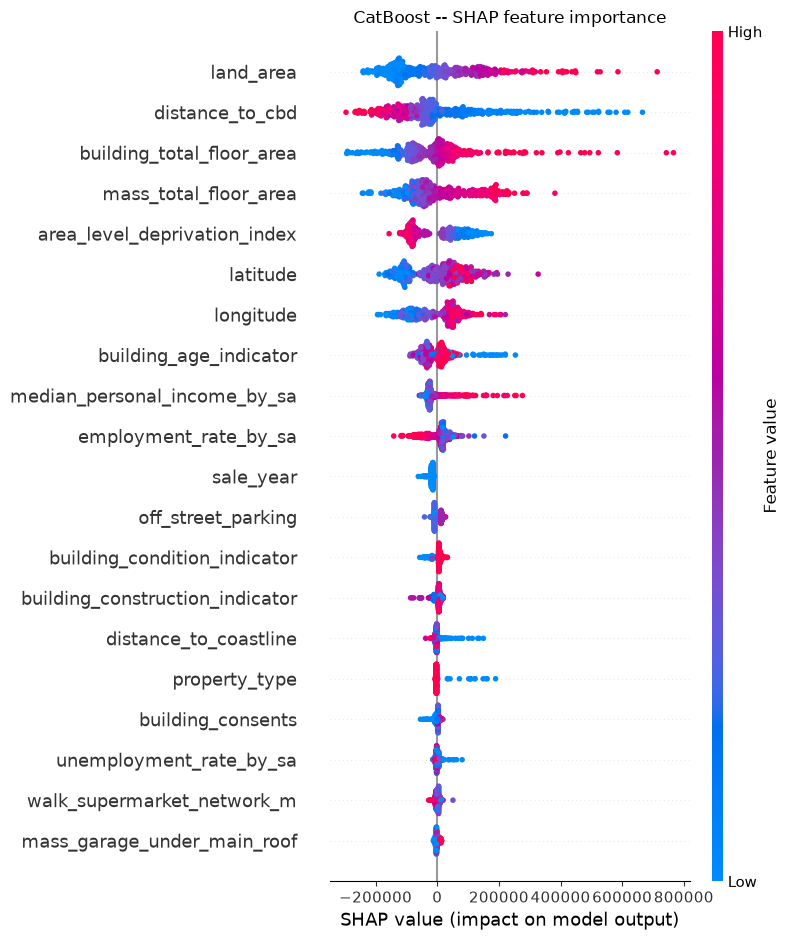

In [10]:
for name, sv in shap_values.items():
    shap.summary_plot(sv, shap_sample, max_display=20, show=False)
    plt.title(f"{name} -- SHAP feature importance")
    plt.tight_layout()
    plt.show()

### 6.2 Side-by-side ranking

Share of each model's total mean |SHAP|, so the three columns are on the
same scale. Sorted by the XGBoost share.

In [11]:
shap_share = pd.DataFrame({
    name: pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS) for name, sv in shap_values.items()
})
shap_share = shap_share / shap_share.sum() * 100
shap_rank = shap_share.rank(ascending=False).astype(int).add_suffix(" rank")

shap_table = pd.concat([shap_share.round(1).add_suffix(" %"), shap_rank], axis=1)
shap_table.sort_values("XGBoost %", ascending=False)

,RandomForest %,XGBoost %,CatBoost %,RandomForest rank,XGBoost rank,CatBoost rank
distance_to_cbd,16.6,16.0,14.2,2,1,2
mass_total_floor_area,24.8,14.0,10.3,1,2,4
land_area,13.8,13.1,14.6,3,3,1
building_total_floor_area,9.7,9.0,10.3,4,4,3
longitude,9.3,8.8,8.2,6,5,7
latitude,9.6,7.4,8.8,5,6,6
area_level_deprivation_index,4.4,6.0,9.1,7,7,5
building_age_indicator,1.9,4.6,4.4,9,8,8
employment_rate_by_sa,1.0,3.2,3.7,11,9,10
median_personal_income_by_sa,2.7,3.0,4.2,8,10,9
